In [26]:
import tensorflow as tf
import keras
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

TensorFlow: 2.15.1
Keras: 2.15.0


In [1]:
# ==========================================================
# Cellule 1 : Imports, paramètres et fonctions
# ==========================================================

import os
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models, regularizers

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
print("ok")


ok


In [13]:
import sys
print("Python :", sys.version)
print("Exécutable :", sys.executable)
%pip --version

Python : 3.14.3 (tags/v3.14.3:323c59a, Feb  3 2026, 16:04:56) [MSC v.1944 64 bit (AMD64)]
Exécutable : c:\Users\MSI\AppData\Local\Python\pythoncore-3.14-64\python.exe
pip 25.3 from c:\Users\MSI\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pip (python 3.14)

Note: you may need to restart the kernel to use updated packages.


In [12]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement tensorflow (from versions: none)

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for tensorflow


In [22]:
import numpy as np
import librosa

# 1. Charger un .npy d'entraînement (AVANT normalisation, donc le .npy brut)
ref = np.load(r"C:\Users\MSI\Desktop\stage ing\spectnumpy_8K\Split_8k_1_BD\Train\Control\AVPEPUDEAC0001a2_segment_1.npy")
print("Forme ref :", ref.shape)          # attendu (257, 59)
print("Mean ref :", ref.mean())
print("Std  ref :", ref.std())

# 2. Recalculer depuis le wav d'origine (1 s)
y, sr = librosa.load(r"C:\Users\MSI\Desktop\pd_project\DATA\Segmented_1\audio\Control\AVPEPUDEAC0001a2_segment_1.wav", sr=8000)

S = librosa.stft(y, n_fft=512, hop_length=128, win_length=512, center=False)
S_db = librosa.amplitude_to_db(np.abs(S))

print("Forme calc :", S_db.shape)        # doit être (257, 59)
print("Mean calc :", S_db.mean())
print("Std  calc :", S_db.std())

# 3. Comparaison
print("Diff moyenne :", np.abs(ref - S_db).mean())

Forme ref : (257, 59)
Mean ref : -32.8312
Std  ref : 15.474774
Forme calc : (257, 59)
Mean calc : -32.8312
Std  calc : 15.474774
Diff moyenne : 0.0


In [23]:
from pathlib import Path
import numpy as np

TRAIN_DIR = Path(r"C:\Users\MSI\Desktop\stage ing\spectnumpy_8K\Split_8k_1_BD\Train")

sums, sq_sums, n = 0.0, 0.0, 0
for cls in ["Control", "Patologicas"]:
    files = list((TRAIN_DIR / cls).glob("*.npy"))
    print(f"{cls}: {len(files)} fichiers")
    for f in files:
        x = np.load(f).astype(np.float64).ravel()
        sums     += x.sum()
        sq_sums  += (x ** 2).sum()
        n        += x.size

mean = sums / n
var  = sq_sums / n - mean ** 2
std  = np.sqrt(var)

print(f"\nNombre total de valeurs : {n:,}")
print(f"MEAN global = {mean:.4f}")
print(f"STD  global = {std:.4f}")

Control: 1218 fichiers
Patologicas: 1498 fichiers

Nombre total de valeurs : 41,182,708
MEAN global = -42.3466
STD  global = 19.0233


In [8]:
# ==========================================================
# Paramètres généraux
# ==========================================================
#1SEC: (257, 122)
#2SEC: (257, 247)
#3SEC: (257, 372)
IMG_HEIGHT = 257
IMG_WIDTH = 59
CHANNELS = 1
size_img= (IMG_HEIGHT, IMG_WIDTH, 1)

BATCH_SIZE = 16

import os
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
CLASS_NAMES = ["Control", "Patologicas"]
print("ok")
import tensorflow as tf
import numpy as np
import random

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print(f"{size_img}")
print("ok")

ok
(257, 59, 1)
ok


In [3]:
import numpy as np

# Chemin vers le fichier .npy
path = r"C:\Users\MSI\Desktop\stage ing\spectnumpy_8K\Split_8k_1_BD\Train\Control\AVPEPUDEAC0001a1_segment_1.npy"
# Charger le fichier
data = np.load(path)

# Afficher la forme du tableau
print("Shape du fichier :", data.shape)

# Récupérer la taille de l'image
IMG_HEIGHT = data.shape[0]
IMG_WIDTH = data.shape[1]

size_img = (IMG_HEIGHT, IMG_WIDTH)

print("size_img =", size_img)

Shape du fichier : (257, 59)
size_img = (257, 59)


In [9]:

def compteur (BD_path, extension):
    classe = ("Control", "Patologicas")
    counts = {}
    for c in classe:
        classe_folder = os.path.join(BD_path, c)
        number_of_files = 0
        for file in os.listdir(classe_folder):
            if file.endswith(extension):
                number_of_files += 1
        counts[c] = number_of_files
        print(f"Number of {extension} files in {c}: {number_of_files}")
    total_files = sum(counts.values())
    print(f"Total number of {extension} files in {BD_path}: {total_files}")


TRAIN_DIR = Path(r"C:\Users\MSI\Desktop\stage ing\spectnumpy_8K\Split_8k_1_BD\Train")
VAL_DIR = Path(r"C:\Users\MSI\Desktop\stage ing\spectnumpy_8K\Split_8k_1_BD\Validation")
extention = ".npy"

compteur(TRAIN_DIR, extention)
compteur(VAL_DIR, extention)

print("ok")


Number of .npy files in Control: 1218
Number of .npy files in Patologicas: 1498
Total number of .npy files in C:\Users\MSI\Desktop\stage ing\spectnumpy_8K\Split_8k_1_BD\Train: 2716
Number of .npy files in Control: 305
Number of .npy files in Patologicas: 375
Total number of .npy files in C:\Users\MSI\Desktop\stage ing\spectnumpy_8K\Split_8k_1_BD\Validation: 680
ok


In [10]:
# ==========================================================
# Cellule : Fonctions SpecAugment
# ==========================================================
import random
import numpy as np

# Une règle pratique est :
# Masque de fréquence : 10 à 15 % de la hauteur de l'image.
# Masque temporel     : 5  à 10 % de la largeur de l'image.
TIME_MASK_WIDTH = 6   
FREQ_MASK_WIDTH = 30   
NB_MASK_t = 1        
NB_MASK_f = 1

def time_mask(spec, nb_mask=NB_MASK_t):
    spec = spec.copy()
    T = spec.shape[1]
    for _ in range(nb_mask):
        width = random.randint(1, TIME_MASK_WIDTH)
        if width > 1 and width < T:
            start = random.randint(1, T - width)
            spec[:, start:start + width, :] = 0
    return spec

def frequency_mask(spec, nb_mask=NB_MASK_f):
    spec = spec.copy()
    F = spec.shape[0]
    for _ in range(nb_mask):
        width = random.randint(1, FREQ_MASK_WIDTH)
        if width > 1 and width < F:
            start = random.randint(1, F - width)
            spec[start:start + width, :, :] = 0
    return spec

def spec_augment(spec):
    spec = spec.numpy() if hasattr(spec, "numpy") else spec
    spec = time_mask(spec)
    spec = frequency_mask(spec)
    return spec.astype(np.float32)

print("Fonctions SpecAugment prêtes (usage offline uniquement).")

Fonctions SpecAugment prêtes (usage offline uniquement).


Chargement des données

Chargement : C:\Users\MSI\Desktop\stage ing\spectnumpy_8K\Split_8k_1_BD\Train
Control        : 1218 fichiers (Label=0)
Patologicas    : 1498 fichiers (Label=1)

Chargement : C:\Users\MSI\Desktop\stage ing\spectnumpy_8K\Split_8k_1_BD\Validation
Control        : 305 fichiers (Label=0)
Patologicas    : 375 fichiers (Label=1)
Mean (train) : -42.3466 ; Std (train) : 19.0233
Images augmentées générées : (2716, 257, 59, 1)
X_train final : (5432, 257, 59, 1)
y_train final : (5432,)
Résumé du dataset
X_train : (5432, 257, 59, 1) ; y_train : (5432,)
X_val : (680, 257, 59, 1) ; y_val : (680,)

Valeur minimale : -3.0307 ; Valeur maximale : 4.2045


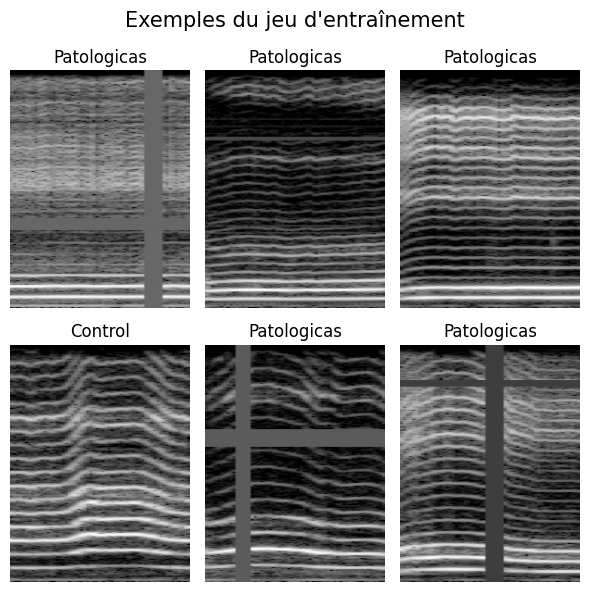

Datasets TensorFlow créés

Chargement terminé avec succès.
ok


In [11]:
# ==========================================================
# Cellule : Chargement, vérification et préparation des données
# ==========================================================
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import random

# ----------------------------------------------------------
# Fonction de chargement des fichiers .npy
# ----------------------------------------------------------
def load_data_from_npy(directory):
    images = []
    labels = []
    print(f"\nChargement : {directory}")
    for label, class_name in enumerate(CLASS_NAMES):
        class_dir = directory / class_name
        files = sorted(class_dir.glob("*.npy"))
        print(f"{class_name:<15}: {len(files)} fichiers (Label={label})")
        for file in files:
            spec = np.load(file).astype(np.float32)
            if spec.shape != (IMG_HEIGHT, IMG_WIDTH):
                print(f"Image ignorée : {file.name} -> {spec.shape}")
                continue
            spec = spec[..., np.newaxis]
            images.append(spec)
            labels.append(label)
    return np.array(images, dtype=np.float32), np.array(labels, dtype=np.int32)

# ==========================================================
# Chargement des données
# ==========================================================
print("Chargement des données")
X_train, y_train = load_data_from_npy(TRAIN_DIR)
X_val, y_val = load_data_from_npy(VAL_DIR)

# ==========================================================
# Normalisation GLOBALE (calculée uniquement sur X_train)
# ==========================================================
train_mean = X_train.mean()
train_std = X_train.std()
print(f"Mean (train) : {train_mean:.4f} ; Std (train) : {train_std:.4f}")
X_train = (X_train - train_mean) / train_std
X_val = (X_val - train_mean) / train_std   # mêmes stats appliquées à val, pas de recalcul !

# ==========================================================
# Génération des versions augmentées (SpecAugment offline)
# Appliqué UNIQUEMENT sur le train set
# ==========================================================
random.seed(SEED)  # reproductibilité du masquage

N_AUG_PER_IMAGE = 1  # 0 = pas d'augmentation (baseline) ; 1+ = nb de copies augmentées par image

if N_AUG_PER_IMAGE > 0:
    X_train_aug = []
    y_train_aug = []
    for i in range(len(X_train)):
        for _ in range(N_AUG_PER_IMAGE):
            aug_spec = spec_augment(X_train[i])
            X_train_aug.append(aug_spec)
            y_train_aug.append(y_train[i])
    X_train_aug = np.array(X_train_aug, dtype=np.float32)
    y_train_aug = np.array(y_train_aug, dtype=np.int32)
    print(f"Images augmentées générées : {X_train_aug.shape}")
    X_train = np.concatenate([X_train, X_train_aug], axis=0)
    y_train = np.concatenate([y_train, y_train_aug], axis=0)
else:
    print("Aucune augmentation appliquée — X_train reste à ses valeurs originales.")

print(f"X_train final : {X_train.shape}")
print(f"y_train final : {y_train.shape}")

# ==========================================================
# Résumé
# ==========================================================
print("Résumé du dataset")
print(f"X_train : {X_train.shape} ; y_train : {y_train.shape}")
print(f"X_val : {X_val.shape} ; y_val : {y_val.shape}")
print()
print(f"Valeur minimale : {X_train.min():.4f} ; Valeur maximale : {X_train.max():.4f}")

# ==========================================================
# Visualisation de quelques spectrogrammes
# ==========================================================
n_images = min(6, len(X_train))
indices = np.random.choice(len(X_train), n_images, replace=False)
plt.figure(figsize=(6,6))
for i, idx in enumerate(indices):
    plt.subplot(2,3,i+1)
    plt.imshow(
        X_train[idx].squeeze(),
        cmap="gray",
        origin="lower",
        aspect="auto"
    )
    plt.title(CLASS_NAMES[y_train[idx]])
    plt.axis("off")
plt.suptitle("Exemples du jeu d'entraînement", fontsize=15)
plt.tight_layout()
plt.show()

# ==========================================================
# Création des datasets TensorFlow
# ==========================================================
with tf.device('/CPU:0'):
    train_ds = (
        tf.data.Dataset
        .from_tensor_slices((X_train, y_train))
        .shuffle(buffer_size=len(X_train), seed=SEED, reshuffle_each_iteration=True)
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )
    val_ds = (
        tf.data.Dataset
        .from_tensor_slices((X_val, y_val))
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )
print("Datasets TensorFlow créés")
print("\nChargement terminé avec succès.")
print("ok")

In [12]:
model = models.Sequential([
    layers.Input(shape=size_img),

    layers.Conv2D(16, (3,3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.25),

    layers.Conv2D(32, (3,3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3,3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3,3), padding="same", activation="relu"),
    layers.Dropout(0.25),

    layers.GlobalAveragePooling2D(),

    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")])
print("ok")

ok


In [13]:

# ==========================================================
# Compilation
# ==========================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.05),
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)
print("ok")

ok


In [14]:
# ==========================================================
# Cellule 7 : Callbacks
# ==========================================================
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau


early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,              # arrête si pas d'amélioration pendant 10 epochs
    restore_best_weights=True,  # récupère automatiquement les meilleurs poids
    verbose=1
)


reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_auc", mode="max",
    factor=0.5,
    patience=5,
    verbose=1
    
)

checkpoint = ModelCheckpoint(
    filepath='best_model.keras',   # ou 'best_model.h5' selon ta version de Keras
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)
print("ok")

ok


In [15]:
# ==========================================================
# Cellule 8 : Entraînement (un seul fit, sans class_weight pour l'instant)
# ==========================================================
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100,
    callbacks=[checkpoint, reduce_lr],   
    verbose=2
)

Epoch 1/100



Epoch 1: val_loss improved from inf to 0.79638, saving model to best_model.keras
340/340 - 18s - loss: 0.6340 - accuracy: 0.6497 - auc: 0.6978 - val_loss: 0.7964 - val_accuracy: 0.5529 - val_auc: 0.6208 - lr: 1.0000e-04 - 18s/epoch - 53ms/step
Epoch 2/100

Epoch 2: val_loss improved from 0.79638 to 0.74573, saving model to best_model.keras
340/340 - 15s - loss: 0.5827 - accuracy: 0.6985 - auc: 0.7710 - val_loss: 0.7457 - val_accuracy: 0.5868 - val_auc: 0.6711 - lr: 1.0000e-04 - 15s/epoch - 44ms/step
Epoch 3/100

Epoch 3: val_loss did not improve from 0.74573
340/340 - 15s - loss: 0.5610 - accuracy: 0.7163 - auc: 0.7914 - val_loss: 0.8220 - val_accuracy: 0.6044 - val_auc: 0.5627 - lr: 1.0000e-04 - 15s/epoch - 45ms/step
Epoch 4/100

Epoch 4: val_loss improved from 0.74573 to 0.73088, saving model to best_model.keras
340/340 - 46s - loss: 0.5397 - accuracy: 0.7410 - auc: 0.8159 - val_loss: 0.7309 - val_accuracy: 0.6412 - val_auc: 0.6778 - lr: 1.0000e-04 - 46s/epoch - 134ms/

43/43 [==============================] - 1s 13ms/step - loss: 0.3732 - accuracy: 0.8838 - auc: 0.9492
Résultats sur le jeu de validation
Loss     : 0.3732
Accuracy : 0.8838
AUC      : 0.9492

Accuracy (sklearn) : 0.8941
Classification Report
              precision    recall  f1-score   support

     Control     0.8607    0.9115    0.8854       305
 Patologicas     0.9244    0.8800    0.9016       375

    accuracy                         0.8941       680
   macro avg     0.8925    0.8957    0.8935       680
weighted avg     0.8958    0.8941    0.8943       680



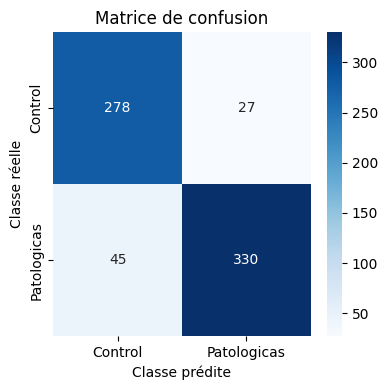

ROC AUC : 0.9494
Seuil optimal suggéré (basé sur ROC) : 0.4273


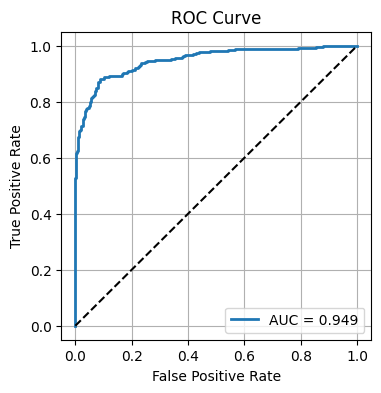

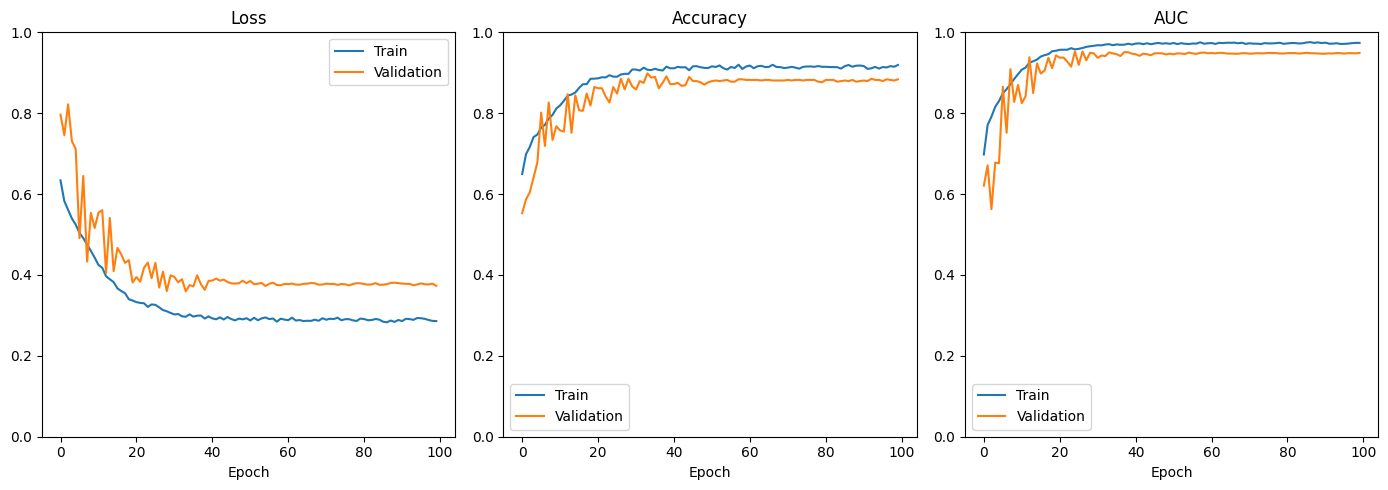

In [17]:
# ==========================================================
# Cellule 9 : Évaluation complète du modèle
# ==========================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score)

# ----------------------------------------------------------
# Evaluation Keras
# ----------------------------------------------------------

loss, accuracy, auc = model.evaluate(val_ds, verbose=1)
print("Résultats sur le jeu de validation")
print(f"Loss     : {loss:.4f}")
print(f"Accuracy : {accuracy:.4f}")
print(f"AUC      : {auc:.4f}")

# ----------------------------------------------------------
# Prédictions
# ----------------------------------------------------------
probabilities = model.predict(val_ds, verbose=0).flatten()
# Récupération des vrais labels
y_true = np.concatenate([
    labels.numpy()
    for _, labels in val_ds
])

# Seuil de décision
threshold = 0.4273

y_pred = (probabilities >= threshold).astype(int)

# ----------------------------------------------------------
# Accuracy
# ----------------------------------------------------------

acc = accuracy_score(y_true, y_pred)

print("\nAccuracy (sklearn) :", round(acc,4))

# ----------------------------------------------------------
# Rapport de classification
# ---------------------------------------------------------

print("Classification Report")

print(classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4
))

# ----------------------------------------------------------
# Matrice de confusion
# ----------------------------------------------------------

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(4,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.title("Matrice de confusion")

plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# ROC AUC
# ----------------------------------------------------------

roc_auc = roc_auc_score(y_true, probabilities)

print(f"ROC AUC : {roc_auc:.4f}")

fpr, tpr, thresholds = roc_curve(y_true, probabilities)

#Calcul du seuil optimal (Youden's J statistic) ---
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]
print(f"Seuil optimal suggéré (basé sur ROC) : {optimal_threshold:.4f}")
# --------------------------------------------------------------

plt.figure(figsize=(4,4))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC = {roc_auc:.3f}"
)

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.grid(True)

plt.show()

# ----------------------------------------------------------
# Courbes d'entraînement
# ----------------------------------------------------------

plt.figure(figsize=(14,5))

# Loss
plt.subplot(1,3,1)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")

plt.ylim(0, 1)
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

# Accuracy
plt.subplot(1,3,2)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.ylim(0, 1)
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

# AUC
plt.subplot(1,3,3)
plt.plot(history.history["auc"], label="Train")
plt.plot(history.history["val_auc"], label="Validation")

plt.ylim(0, 1)
plt.title("AUC")
plt.xlabel("Epoch")
plt.legend()
plt.tight_layout()    #Elle évite que les titres, les axes ou les légendes se chevauchent.
plt.show()

 Seuil  Sensibilité  Spécificité  Précision  Accuracy     F1  Faux Négatifs  Faux Positifs
  0.10       0.9653       0.6098     0.7526    0.8059 0.8458             13            119
  0.16       0.9493       0.6885     0.7894    0.8324 0.8620             19             95
  0.23       0.9227       0.7770     0.8357    0.8574 0.8771             29             68
  0.30       0.9013       0.8295     0.8667    0.8691 0.8837             37             52
  0.40       0.8880       0.8918     0.9098    0.8897 0.8988             42             33
  0.50       0.8480       0.9279     0.9353    0.8838 0.8895             57             22
  0.70       0.7280       0.9738     0.9715    0.8382 0.8323            102              8


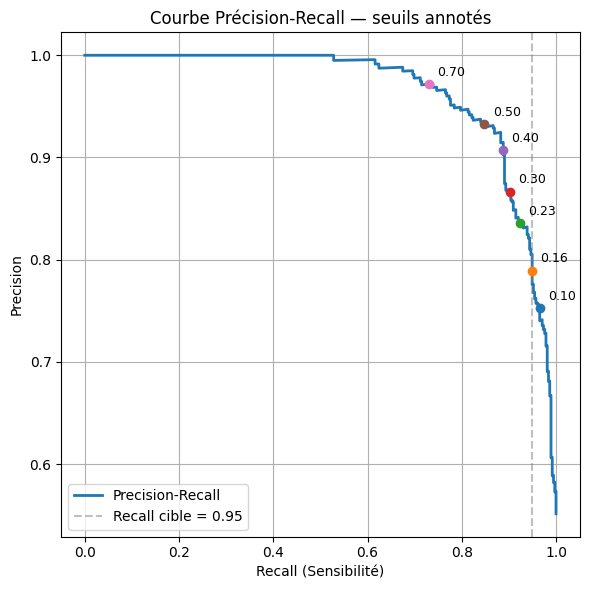

In [18]:
# ==========================================================
# Courbe Précision-Recall avec seuils annotés
# ==========================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve, confusion_matrix, f1_score

precision, recall, thresholds = precision_recall_curve(y_true, probabilities)

# ----------------------------------------------------------
# Tableau récapitulatif pour plusieurs seuils cibles
# ----------------------------------------------------------
candidate_thresholds = [0.10, 0.16, 0.23, 0.30, 0.40, 0.50, 0.70]

rows = []
for t in candidate_thresholds:
    y_pred_t = (probabilities >= t).astype(int)
    cm = confusion_matrix(y_true, y_pred_t)
    tn, fp, fn, tp = cm.ravel()
    sens = tp / (tp + fn)          # recall Patologicas
    spec = tn / (tn + fp)          # recall Control
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    acc  = (tp + tn) / (tp + tn + fp + fn)
    f1   = f1_score(y_true, y_pred_t)
    rows.append([t, sens, spec, prec, acc, f1, fn, fp])

df_thresholds = pd.DataFrame(
    rows,
    columns=["Seuil", "Sensibilité", "Spécificité", "Précision",
             "Accuracy", "F1", "Faux Négatifs", "Faux Positifs"]
)
print(df_thresholds.round(4).to_string(index=False))

# ----------------------------------------------------------
# Graphique Précision-Recall
# ----------------------------------------------------------
plt.figure(figsize=(6, 6))
plt.plot(recall, precision, linewidth=2, label="Precision-Recall")

# Annoter quelques seuils clés sur la courbe
for t in candidate_thresholds:
    idx = np.argmin(np.abs(thresholds - t))
    plt.scatter(recall[idx], precision[idx], zorder=5)
    plt.annotate(
        f"{t:.2f}",
        (recall[idx], precision[idx]),
        textcoords="offset points", xytext=(6, 6), fontsize=9
    )

plt.axvline(0.95, color="gray", linestyle="--", alpha=0.5, label="Recall cible = 0.95")
plt.xlabel("Recall (Sensibilité)")
plt.ylabel("Precision")
plt.title("Courbe Précision-Recall — seuils annotés")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
from sklearn.metrics import precision_recall_curve, confusion_matrix

precision, recall, thresholds = precision_recall_curve(y_true, probabilities)

# On veut recall (sensibilité) sur Patologicas >= 0.95
target_recall = 0.95
valid_idx = np.where(recall[:-1] >= target_recall)[0]  # thresholds a 1 élément de moins
if len(valid_idx) > 0:
    idx = valid_idx[-1]  # seuil le plus élevé qui respecte encore la contrainte
    new_threshold = thresholds[idx]
    print(f"Seuil pour recall >= {target_recall} : {new_threshold:.4f}")
    print(f"Précision correspondante : {precision[idx]:.4f}")

    y_pred_new = (probabilities >= new_threshold).astype(int)
    cm_new = confusion_matrix(y_true, y_pred_new)
    print("Nouvelle matrice de confusion :\n", cm_new)
else:
    print("Aucun seuil n'atteint ce recall dans les données.")

Seuil pour recall >= 0.95 : 0.1483
Précision correspondante : 0.7761
Nouvelle matrice de confusion :
 [[202 103]
 [ 18 357]]


In [21]:
# ==========================================================
# Cellule 8 : Sauvegarde du modèle
# ==========================================================

from pathlib import Path

# ----------------------------------------------------------
# Dossier de sauvegarde
# ----------------------------------------------------------

SAVE_DIR = Path(r"C:\Users\MSI\Desktop\stage ing\best_model")
SAVE_DIR.mkdir(exist_ok=True)

# ----------------------------------------------------------
# Sauvegarde du modèle complet
# ----------------------------------------------------------

model_path = SAVE_DIR / "best_model_cnn.keras"

model.save(model_path)

print("✓ Modèle sauvegardé avec succès.")
print("Emplacement :", model_path)

# ----------------------------------------------------------
# Sauvegarde des poids uniquement (optionnel)
# ----------------------------------------------------------

model.save_weights(Path(SAVE_DIR) / "best_model_cnn.h5")


print("✓ Poids sauvegardés.")
print("Emplacement :", Path(SAVE_DIR) / "best_model_cnn.h5")

✓ Modèle sauvegardé avec succès.
Emplacement : C:\Users\MSI\Desktop\stage ing\best_model\best_model_cnn.keras
✓ Poids sauvegardés.
Emplacement : C:\Users\MSI\Desktop\stage ing\best_model\best_model_cnn.h5


In [28]:
import tensorflow as tf
from pathlib import Path

# Chemin vers votre modèle dans le projet
MODEL_PATH = Path(r"C:\Users\MSI\Desktop\projets\ParkinVoiceApp\backend\models_ia\best_model_cnn.keras")

print("TF:", tf.__version__)
print("Keras:", keras.__version__)
print(f"Fichier existe : {MODEL_PATH.exists()}")
print(f"Taille : {MODEL_PATH.stat().st_size} bytes")

# Chargement
model = tf.keras.models.load_model(str(MODEL_PATH))
print("\n✅ Modèle chargé avec succès !")
print(f"Input shape  : {model.input_shape}")
print(f"Output shape : {model.output_shape}")
print(f"Nombre de couches : {len(model.layers)}")

TF: 2.15.1
Keras: 2.15.0
Fichier existe : True
Taille : 831587 bytes

✅ Modèle chargé avec succès !
Input shape  : (None, 257, 59, 1)
Output shape : (None, 1)
Nombre de couches : 17


In [29]:
from pathlib import Path
import os

# Dossier de destination
MODEL_DIR = Path(r"C:\Users\MSI\Desktop\projets\ParkinVoiceApp\backend\models_ia")

# Export 1 : .h5 legacy (le plus compatible entre Keras 2 et 3)
h5_path = MODEL_DIR / "best_model_cnn_legacy.h5"
model.save(str(h5_path), save_format="h5")
print(f"✅ Sauvegardé : {h5_path.name}")
print(f"   Taille : {h5_path.stat().st_size:,} bytes")
print()

# Export 2 : .keras avec Keras 2 (même version que le notebook)
keras_path = MODEL_DIR / "best_model_cnn_v2.keras"
model.save(str(keras_path))
print(f"✅ Sauvegardé : {keras_path.name}")
print(f"   Taille : {keras_path.stat().st_size:,} bytes")

✅ Sauvegardé : best_model_cnn_legacy.h5
   Taille : 841,480 bytes

✅ Sauvegardé : best_model_cnn_v2.keras
   Taille : 831,587 bytes


c:\Users\MSI\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [30]:
import h5py

h5_path = r"C:\Users\MSI\Desktop\projets\ParkinVoiceApp\backend\models_ia\best_model_cnn_legacy.h5"

with h5py.File(h5_path, "r") as f:
    print("Attributs du fichier .h5 :")
    for key in f.attrs.keys():
        print(f"  - {key}")
    
    print()
    print("Contient 'model_config' :", "model_config" in f.attrs)
    print("Contient 'layer_names'  :", "layer_names" in f.attrs)
    
    if "layer_names" in f.attrs:
        layers = f.attrs["layer_names"]
        print(f"Nombre de couches : {len(layers)}")

Attributs du fichier .h5 :
  - backend
  - keras_version
  - model_config
  - training_config

Contient 'model_config' : True
Contient 'layer_names'  : False
